# 1. Data Cleaning Part
Prepare the data for analysis by handling missing values, removing duplicates, correcting data types, and organizing the dataset to ensure data quality, consistency, and accuracy.

In [1]:
# Import essential packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Read required data
orders = pd.read_excel(
    'C:/Users/SaudMaashi/Desktop/My Projects/Data Analytics Projects/SuperStore Data (Python + Power BI)/Data/superstore_dirty.xls',
    sheet_name = 'Orders')
returns = pd.read_excel(
    'C:/Users/SaudMaashi/Desktop/My Projects/Data Analytics Projects/SuperStore Data (Python + Power BI)/Data/superstore_dirty.xls',
    sheet_name = 'Returns')

In [3]:
orders.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [4]:
returns.head()

,Order ID,Returned
0,US-2023-100762,Yes
1,US-2023-100867,Yes
2,US-2023-102652,Yes
3,US-2023-103373,Yes
4,US-2023-103744,Yes


In [5]:
# Remove unnecessary columns
orders = orders.drop(columns= ['Row ID', 'Customer ID', 'Customer Name', 'Segment',
                               'State/Province', 'Postal Code', 'Region', 'Sub-Category'])
# Change Country/Region column name to be Country
orders = orders.rename(columns= {'Country/Region': 'Country'})

In [6]:
# Merge the Orders and Returns tables, while keeping all orders
# Mark matched Order IDs as "Yes" and non-matched Order IDs as "No"
merged = orders.merge(
    returns[['Order ID']].drop_duplicates().assign(Returned='Yes'),
    on = 'Order ID',
    how = 'left'
)
# Check the new merged table
merged.head()

,Order ID,Order Date,Ship Date,Ship Mode,Country,City,Product ID,Category,Product Name,Sales,Quantity,Discount,Profit,Returned
0,US-2023-103800,2023-01-03,2023-01-07,Standard Class,United States,Houston,OFF-PA-10000174,Office Supplies,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512,NaN
1,US-2023-112326,2023-01-04,2023-01-08,Standard Class,United States,Naperville,OFF-BI-10004094,Office Supplies,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870,NaN
2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,United States,Naperville,OFF-LA-10003223,Office Supplies,Avery 508,11.784,3,0.2,4.2717,NaN
3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,United States,Naperville,OFF-ST-10002743,Office Supplies,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748,NaN
4,US-2023-141817,2023-01-05,2023-01-12,Standard Class,United States,Philadelphia,OFF-AR-10003478,Office Supplies,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840,NaN


In [7]:
# Fill every NaN (null value) in the merged table to "No"
merged = merged.fillna("No")
merged

,Order ID,Order Date,Ship Date,Ship Mode,Country,City,Product ID,Category,Product Name,Sales,Quantity,Discount,Profit,Returned
0,US-2023-103800,2023-01-03,2023-01-07,Standard Class,United States,Houston,OFF-PA-10000174,Office Supplies,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512,No
1,US-2023-112326,2023-01-04,2023-01-08,Standard Class,United States,Naperville,OFF-BI-10004094,Office Supplies,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870,No
2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,United States,Naperville,OFF-LA-10003223,Office Supplies,Avery 508,11.784,3,0.2,4.2717,No
3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,United States,Naperville,OFF-ST-10002743,Office Supplies,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748,No
4,US-2023-141817,2023-01-05,2023-01-12,Standard Class,United States,Philadelphia,OFF-AR-10003478,Office Supplies,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10189,US-2026-143259,2026-12-30,2027-01-03,Standard Class,United States,New York City,OFF-BI-10003684,Office Supplies,Wilson Jones Legal Size Ring Binders,52.776,3,0.2,19.7910,No
10190,US-2026-115427,2026-12-30,2027-01-03,Standard Class,United States,Fairfield,OFF-BI-10004632,Office Supplies,GBC Binding covers,20.720,2,0.2,6.4750,Yes
10191,US-2026-156720,2026-12-30,2027-01-03,Standard Class,United States,Loveland,OFF-FA-10003472,Office Supplies,Bagged Rubber Bands,3.024,3,0.2,-0.6048,No
10192,US-2026-143259,2026-12-30,2027-01-03,Standard Class,United States,New York City,TEC-PH-10004774,Technology,Gear Head AU3700S Headset,90.930,7,0.0,2.7279,No


In [8]:
# Check data types for all columns
merged.info()
# Change 'Retunred' column's type to be boolean
merged.astype({'Returned': bool})

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Order ID      10194 non-null  object        
 1   Order Date    10194 non-null  datetime64[ns]
 2   Ship Date     10194 non-null  datetime64[ns]
 3   Ship Mode     10194 non-null  object        
 4   Country       10194 non-null  object        
 5   City          10194 non-null  object        
 6   Product ID    10194 non-null  object        
 7   Category      10194 non-null  object        
 8   Product Name  10194 non-null  object        
 9   Sales         10194 non-null  float64       
 10  Quantity      10194 non-null  int64         
 11  Discount      10194 non-null  float64       
 12  Profit        10194 non-null  float64       
 13  Returned      10194 non-null  object        
dtypes: datetime64[ns](2), float64(3), int64(1), object(8)
memory usage: 1.1+ MB


,Order ID,Order Date,Ship Date,Ship Mode,Country,City,Product ID,Category,Product Name,Sales,Quantity,Discount,Profit,Returned
0,US-2023-103800,2023-01-03,2023-01-07,Standard Class,United States,Houston,OFF-PA-10000174,Office Supplies,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512,True
1,US-2023-112326,2023-01-04,2023-01-08,Standard Class,United States,Naperville,OFF-BI-10004094,Office Supplies,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870,True
2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,United States,Naperville,OFF-LA-10003223,Office Supplies,Avery 508,11.784,3,0.2,4.2717,True
3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,United States,Naperville,OFF-ST-10002743,Office Supplies,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748,True
4,US-2023-141817,2023-01-05,2023-01-12,Standard Class,United States,Philadelphia,OFF-AR-10003478,Office Supplies,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10189,US-2026-143259,2026-12-30,2027-01-03,Standard Class,United States,New York City,OFF-BI-10003684,Office Supplies,Wilson Jones Legal Size Ring Binders,52.776,3,0.2,19.7910,True
10190,US-2026-115427,2026-12-30,2027-01-03,Standard Class,United States,Fairfield,OFF-BI-10004632,Office Supplies,GBC Binding covers,20.720,2,0.2,6.4750,True
10191,US-2026-156720,2026-12-30,2027-01-03,Standard Class,United States,Loveland,OFF-FA-10003472,Office Supplies,Bagged Rubber Bands,3.024,3,0.2,-0.6048,True
10192,US-2026-143259,2026-12-30,2027-01-03,Standard Class,United States,New York City,TEC-PH-10004774,Technology,Gear Head AU3700S Headset,90.930,7,0.0,2.7279,True


In [9]:
# Add a new column named 'Delivery Time (in Days)' to help us calculate how fast a order is delivered
merged['Delivery Time (in Days)'] = merged['Ship Date'] - merged['Order Date']
merged['Delivery Time (in Days)'] = merged['Delivery Time (in Days)'].dt.days.astype('int64')
merged['Delivery Time (in Days)']

0        4
1        4
2        4
3        4
4        7
        ..
10189    4
10190    4
10191    4
10192    4
10193    4
Name: Delivery Time (in Days), Length: 10194, dtype: int64

In [10]:
# 'Ship Mode' column normalization
merged['Ship Mode'] = merged['Ship Mode'].apply(lambda x: x.split()[0] if x != 'Same Day' else 'Same-Day')

In [11]:
# Rename the column 'Profit' column to be more descriptivable 
merged = merged.rename(columns= {'Profit': 'Net Result'})
merged.head()

,Order ID,Order Date,Ship Date,Ship Mode,Country,City,Product ID,Category,Product Name,Sales,Quantity,Discount,Net Result,Returned,Delivery Time (in Days)
0,US-2023-103800,2023-01-03,2023-01-07,Standard,United States,Houston,OFF-PA-10000174,Office Supplies,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512,No,4
1,US-2023-112326,2023-01-04,2023-01-08,Standard,United States,Naperville,OFF-BI-10004094,Office Supplies,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870,No,4
2,US-2023-112326,2023-01-04,2023-01-08,Standard,United States,Naperville,OFF-LA-10003223,Office Supplies,Avery 508,11.784,3,0.2,4.2717,No,4
3,US-2023-112326,2023-01-04,2023-01-08,Standard,United States,Naperville,OFF-ST-10002743,Office Supplies,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748,No,4
4,US-2023-141817,2023-01-05,2023-01-12,Standard,United States,Philadelphia,OFF-AR-10003478,Office Supplies,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840,No,7


In [12]:
# Create a new boolean column that states if an order had a profit or loss
merged['Net Result Status'] = merged['Net Result'].apply(
    lambda result: 'Gain' if result > 0 else 'Loss'
)
merged.head()

,Order ID,Order Date,Ship Date,Ship Mode,Country,City,Product ID,Category,Product Name,Sales,Quantity,Discount,Net Result,Returned,Delivery Time (in Days),Net Result Status
0,US-2023-103800,2023-01-03,2023-01-07,Standard,United States,Houston,OFF-PA-10000174,Office Supplies,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512,No,4,Gain
1,US-2023-112326,2023-01-04,2023-01-08,Standard,United States,Naperville,OFF-BI-10004094,Office Supplies,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870,No,4,Loss
2,US-2023-112326,2023-01-04,2023-01-08,Standard,United States,Naperville,OFF-LA-10003223,Office Supplies,Avery 508,11.784,3,0.2,4.2717,No,4,Gain
3,US-2023-112326,2023-01-04,2023-01-08,Standard,United States,Naperville,OFF-ST-10002743,Office Supplies,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748,No,4,Loss
4,US-2023-141817,2023-01-05,2023-01-12,Standard,United States,Philadelphia,OFF-AR-10003478,Office Supplies,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840,No,7,Gain


In [13]:
# Re-order the columns
merged = merged[[
    'Order ID',
    'Order Date',
    'Ship Date',
    'Ship Mode',
    'Delivery Time (in Days)',
    'Country',
    'City',
    'Product ID',
    'Product Name',
    'Category',
    'Sales',
    'Quantity',
    'Discount',
    'Net Result',
    'Net Result Status',
    'Returned',  
]]

merged.head()

,Order ID,Order Date,Ship Date,Ship Mode,Delivery Time (in Days),Country,City,Product ID,Product Name,Category,Sales,Quantity,Discount,Net Result,Net Result Status,Returned
0,US-2023-103800,2023-01-03,2023-01-07,Standard,4,United States,Houston,OFF-PA-10000174,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",Office Supplies,16.448,2,0.2,5.5512,Gain,No
1,US-2023-112326,2023-01-04,2023-01-08,Standard,4,United States,Naperville,OFF-BI-10004094,GBC Standard Plastic Binding Systems Combs,Office Supplies,3.540,2,0.8,-5.4870,Loss,No
2,US-2023-112326,2023-01-04,2023-01-08,Standard,4,United States,Naperville,OFF-LA-10003223,Avery 508,Office Supplies,11.784,3,0.2,4.2717,Gain,No
3,US-2023-112326,2023-01-04,2023-01-08,Standard,4,United States,Naperville,OFF-ST-10002743,SAFCO Boltless Steel Shelving,Office Supplies,272.736,3,0.2,-64.7748,Loss,No
4,US-2023-141817,2023-01-05,2023-01-12,Standard,7,United States,Philadelphia,OFF-AR-10003478,Avery Hi-Liter EverBold Pen Style Fluorescent ...,Office Supplies,19.536,3,0.2,4.8840,Gain,No


In [14]:
merged.to_csv('C:/Users/SaudMaashi/Desktop/My Projects/Data Analytics Projects/SuperStore Data (Python + Power BI)/Data/superstore_clean.csv', index = False)

# 2. Data Visualization & Analysis
Analyze the cleaned dataset using statistical calculations and visualizations to identify sales trends, evaluate business performance, compare product categories, and uncover patterns that support data-driven decision-making

In [15]:
# Copy the cleaned DataFrame to perform operations on it rather than the original one
df = merged.copy()
df.head()

,Order ID,Order Date,Ship Date,Ship Mode,Delivery Time (in Days),Country,City,Product ID,Product Name,Category,Sales,Quantity,Discount,Net Result,Net Result Status,Returned
0,US-2023-103800,2023-01-03,2023-01-07,Standard,4,United States,Houston,OFF-PA-10000174,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",Office Supplies,16.448,2,0.2,5.5512,Gain,No
1,US-2023-112326,2023-01-04,2023-01-08,Standard,4,United States,Naperville,OFF-BI-10004094,GBC Standard Plastic Binding Systems Combs,Office Supplies,3.540,2,0.8,-5.4870,Loss,No
2,US-2023-112326,2023-01-04,2023-01-08,Standard,4,United States,Naperville,OFF-LA-10003223,Avery 508,Office Supplies,11.784,3,0.2,4.2717,Gain,No
3,US-2023-112326,2023-01-04,2023-01-08,Standard,4,United States,Naperville,OFF-ST-10002743,SAFCO Boltless Steel Shelving,Office Supplies,272.736,3,0.2,-64.7748,Loss,No
4,US-2023-141817,2023-01-05,2023-01-12,Standard,7,United States,Philadelphia,OFF-AR-10003478,Avery Hi-Liter EverBold Pen Style Fluorescent ...,Office Supplies,19.536,3,0.2,4.8840,Gain,No


In [16]:
# Copy the cleaned DataFrame to perform operations on it rather than the original one
df = merged.copy()
# Calculate total sales
total_sales = df['Sales'].sum()
print(f'Total Sales: {total_sales:.0f}')
# Calculate total discount
total_discounts = df['Discount'].sum()
print(f'Total Discounts: {total_discounts:.0f}')
# Calculate discounts average
average_discounts = df['Discount'].mean()
print(f'Average Discounts: {average_discounts:.2f}')
# ---------------------------
# Calculate the number of rows and columns in the whole DataFrame
df_shape = df.shape
print('Number of Rows & Columns, respectively:', df.shape)
# ---------------------------
# Calculate the total of net result
total_net_result = round(df['Net Result'].sum(), 2)
print(f'Total Net Result: {total_net_result:.0f}')
# ---------------------------
# Calculate average delivery time (in days)
average_delivery_time = df['Delivery Time (in Days)'].mean()
print(f'Average Delivery Time: {average_delivery_time:.1f}')
# ---------------------------
# Calculate number of returned items
returned_items_count = (df['Returned'] == 'Yes').sum()
print(f'Returned Items Count: {returned_items_count}')

Total Sales: 2326534
Total Discounts: 1584
Average Discounts: 0.16
Number of Rows & Columns, respectively: (10194, 16)
Total Net Result: 292297
Average Delivery Time: 4.0
Returned Items Count: 800


### Analysis & Conclusion:
The descriptive statistics of most values has been calculated and shown above.

In [17]:
# Store unique categories as a list
categories_list = df['Category'].unique().tolist()
categories_list

['Office Supplies', 'Furniture', 'Technology']

In [18]:
# Show the sales of each category
# For "Office Supplies"
office_supplies_sales = df[df['Category'] == 'Office Supplies']['Sales'].sum()
print(f'Total Sales of "Office Supplies: {office_supplies_sales:.0f}')
# ---------------------------
# For "Furniture"
furniture_sales = df[df['Category'] == 'Furniture']['Sales'].sum()
print(f'Total Sales of "Furniture: {furniture_sales:.0f}')
# ---------------------------
# For "Technology"
technology_sales = df[df['Category'] == 'Technology']['Sales'].sum()
print(f'Total Sales of "Technology: {technology_sales:.0f}')

sales_list = [office_supplies_sales, furniture_sales, technology_sales]
category_colors = ["darkred", "darkblue", "darkgreen"]

Total Sales of "Office Supplies: 731893
Total Sales of "Furniture: 754748
Total Sales of "Technology: 839893


### Analysis & Conclusion:
It can be easily seen that sales are evenly separated between the categories.

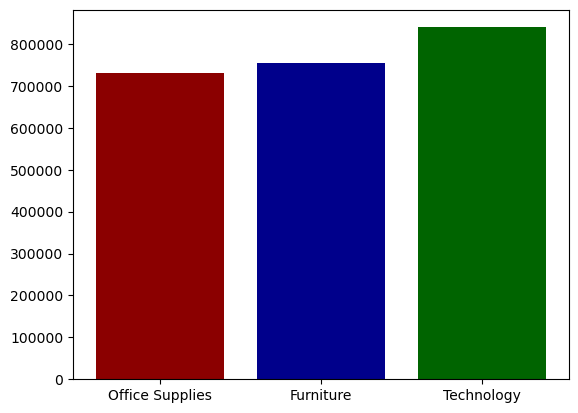

In [19]:
# Show sales of categories visually
plt.bar(categories_list, sales_list, color = category_colors);

### Analysis & Conclusion:
The histogram shown above is a visual evidence for the fact mentioned above.

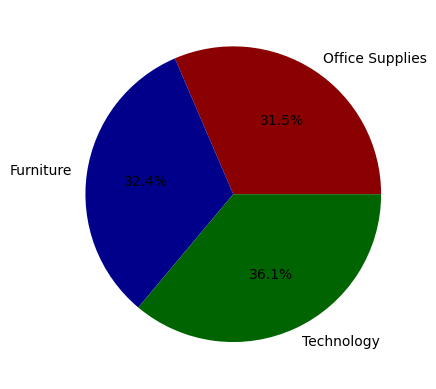

In [20]:
# Use total_sales from previous cell to calcualate
# the contribution percentage of each category
categories_percentage = [(sale / total_sales) * 100 for sale in sales_list]
# Display Pie Chart for each category percentage
plt.pie(
    categories_percentage,
    labels = categories_list,
    autopct = '%1.1f%%',
    colors = category_colors,
);

### Analysis & Conclusion:
The pie chart supports the fact that there is no dominant category over others, as shown in the histogram above.

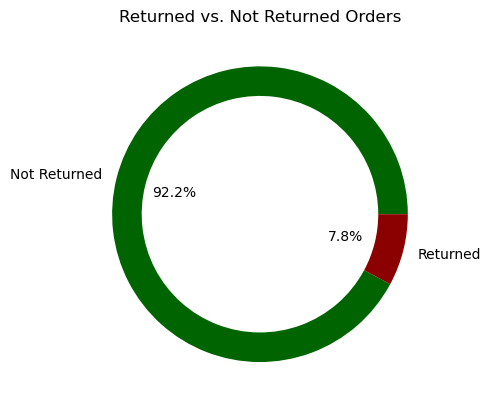

In [50]:
# Create a pie chart to represent the number of returned and not returned items
returns_count = df['Returned'].value_counts()
plt.pie(
    returns_count,
    labels= ['Not Returned', 'Returned'],
    autopct='%1.1f%%',
    colors=['darkgreen', 'darkred'],
    wedgeprops={"width": 0.2},
)

plt.title('Returned vs. Not Returned Orders')
plt.show()

### Analysis & Conclusion:
Only about 8% of the orders has been returned, others were successfully completed. 